# ============================================================
# NETGUARD AI
# Notebook 09 - Autoencoder Classification
# ============================================================

"""
Objective:
Evaluate whether the Autoencoder's latent representation
can support effective DDoS traffic classification.

Scientific Question:
Can compressed Autoencoder features provide competitive
classification performance compared with the original
selected features?
"""

In [31]:
import pandas as pd
import numpy as np
import time

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [32]:
# Load Autoencoder Features



train_df = pd.read_csv(
    "autoencoder_encoded_train.csv"
)

test_df = pd.read_csv(
    "autoencoder_encoded_test.csv"
)

print("Training shape:", train_df.shape)
print("Testing shape :", test_df.shape)

Training shape: (178465, 17)
Testing shape : (44617, 17)


In [33]:
# Separate X and y
X_train = train_df.drop("Label", axis=1)
y_train = train_df["Label"]

X_test = test_df.drop("Label", axis=1)
y_test = test_df["Label"]

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

X_train: (178465, 16)
X_test : (44617, 16)


In [34]:
# Encode Labels
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

print("Class mapping:")

for i, class_name in enumerate(label_encoder.classes_):
    print(i, "=", class_name)

Class mapping:
0 = BENIGN
1 = DDoS


In [35]:
y_test,y_test_encoded

(0        BENIGN
 1          DDoS
 2        BENIGN
 3          DDoS
 4          DDoS
           ...  
 44612    BENIGN
 44613      DDoS
 44614      DDoS
 44615      DDoS
 44616      DDoS
 Name: Label, Length: 44617, dtype: object,
 array([0, 1, 0, ..., 1, 1, 1], shape=(44617,)))

In [36]:
# Scale Latent Features for Logistic Regression

# The Autoencoder's latent values can still have different scales.

# We'll scale them for Logistic Regression.

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

# Tree models will use the original latent values.

In [37]:
results = []

In [38]:
# Logistic Regression
start_time = time.time()

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(
    X_train_scaled,
    y_train_encoded
)

training_time = time.time() - start_time

y_pred = lr_model.predict(X_test_scaled)

y_prob = lr_model.predict_proba(
    X_test_scaled
)[:, 1]





In [39]:
from sklearn.metrics import confusion_matrix

def calculate_fnr(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return fn / (fn + tp) * 100 if (fn + tp) > 0 else 0

In [40]:
fnr = calculate_fnr(y_test_encoded, y_pred)

print(f"Logistic Regression FNR: {fnr:.2f}%")

Logistic Regression FNR: 0.12%


In [41]:
results.append({
    "Model": "Autoencoder + Logistic Regression",
    "Accuracy": accuracy_score(
        y_test_encoded,
        y_pred
    ),
    "Precision": precision_score(
        y_test_encoded,
        y_pred
    ),
    "Recall": recall_score(
        y_test_encoded,
        y_pred
    ),
    "F1": f1_score(
        y_test_encoded,
        y_pred
    ),
    "ROC-AUC": roc_auc_score(
        y_test_encoded,
        y_prob
    ),
    "Training Time": training_time,
    "FNR (%)": fnr
})

print("Logistic Regression completed.")

Logistic Regression completed.


In [42]:
# Decision Tree
start_time = time.time()

dt_model = DecisionTreeClassifier(
    random_state=42
)

dt_model.fit(
    X_train,
    y_train_encoded
)

training_time = time.time() - start_time

y_pred = dt_model.predict(X_test)

y_prob = dt_model.predict_proba(
    X_test
)[:, 1]



In [43]:
from sklearn.metrics import confusion_matrix

def calculate_fnr(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return fn / (fn + tp) * 100 if (fn + tp) > 0 else 0

In [44]:

fnr = calculate_fnr(y_test_encoded, y_pred)

print(f"DecisionTreeClassifier FNR: {fnr:.2f}%")

DecisionTreeClassifier FNR: 0.03%


In [45]:
results.append({
    "Model": "Autoencoder + Decision Tree",
    "Accuracy": accuracy_score(
        y_test_encoded,
        y_pred
    ),
    "Precision": precision_score(
        y_test_encoded,
        y_pred
    ),
    "Recall": recall_score(
        y_test_encoded,
        y_pred
    ),
    "F1": f1_score(
        y_test_encoded,
        y_pred
    ),
    "ROC-AUC": roc_auc_score(
        y_test_encoded,
        y_prob
    ),
    "Training Time": training_time,
    "FNR (%)": fnr
})

print("Decision Tree completed.")

Decision Tree completed.


In [46]:
# Random Forest
start_time = time.time()

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train,
    y_train_encoded
)

training_time = time.time() - start_time

y_pred = rf_model.predict(X_test)

y_prob = rf_model.predict_proba(
    X_test
)[:, 1]



In [47]:
from sklearn.metrics import confusion_matrix

def calculate_fnr(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return fn / (fn + tp) * 100 if (fn + tp) > 0 else 0

In [48]:

fnr = calculate_fnr(y_test_encoded, y_pred)

print(f"Random Forest FNR: {fnr:.2f}%")

Random Forest FNR: 0.04%


In [49]:
results.append({
    "Model": "Autoencoder + Random Forest",
    "Accuracy": accuracy_score(
        y_test_encoded,
        y_pred
    ),
    "Precision": precision_score(
        y_test_encoded,
        y_pred
    ),
    "Recall": recall_score(
        y_test_encoded,
        y_pred
    ),
    "F1": f1_score(
        y_test_encoded,
        y_pred
    ),
    "ROC-AUC": roc_auc_score(
        y_test_encoded,
        y_prob
    ),
    "Training Time": training_time,
    "FNR (%)": fnr
})

print("Random Forest completed.")

Random Forest completed.


In [50]:
# Compare Autoencoder Classifiers
ae_results = pd.DataFrame(results)

ae_results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Training Time,FNR (%)
0,Autoencoder + Logistic Regression,0.986911,0.978796,0.998828,0.988711,0.999256,1.218027,0.117174
1,Autoencoder + Decision Tree,0.999485,0.999414,0.999688,0.999551,0.999449,7.476504,0.031246
2,Autoencoder + Random Forest,0.999641,0.999766,0.999609,0.999688,0.999999,18.252770,0.039058


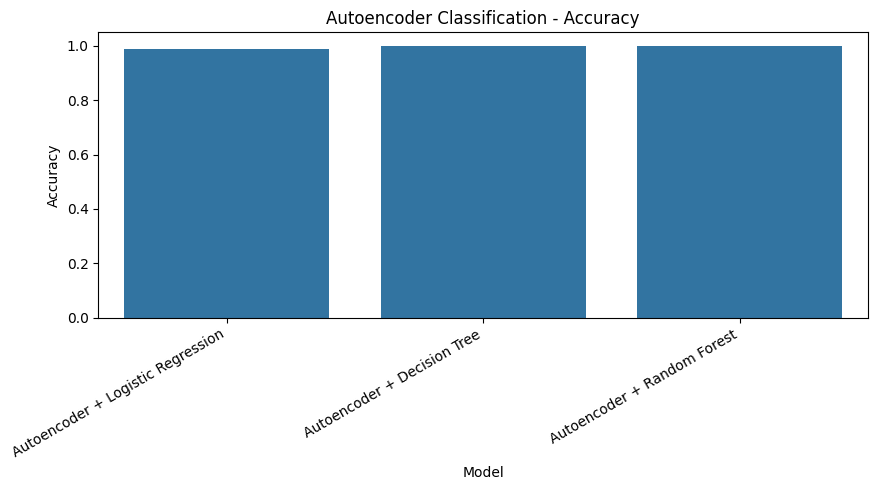

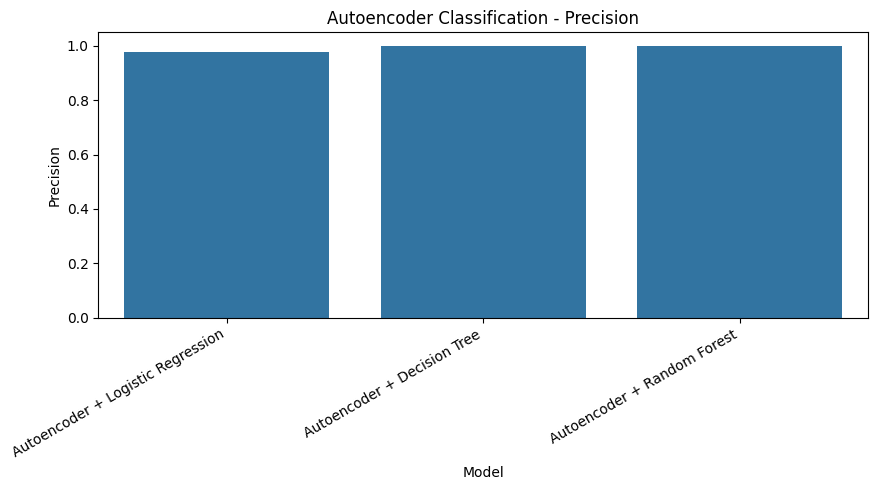

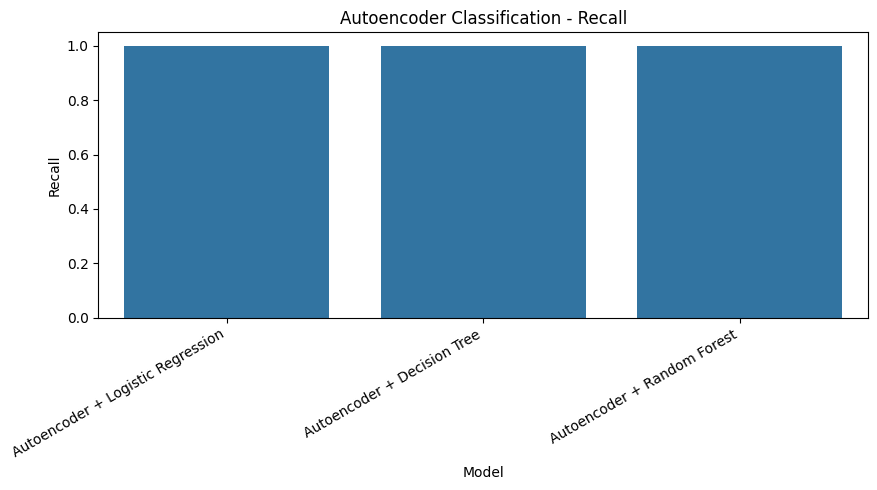

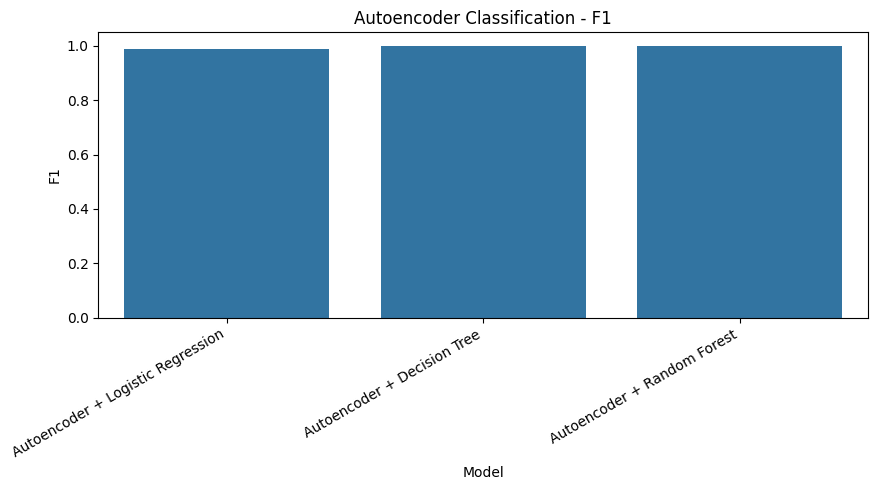

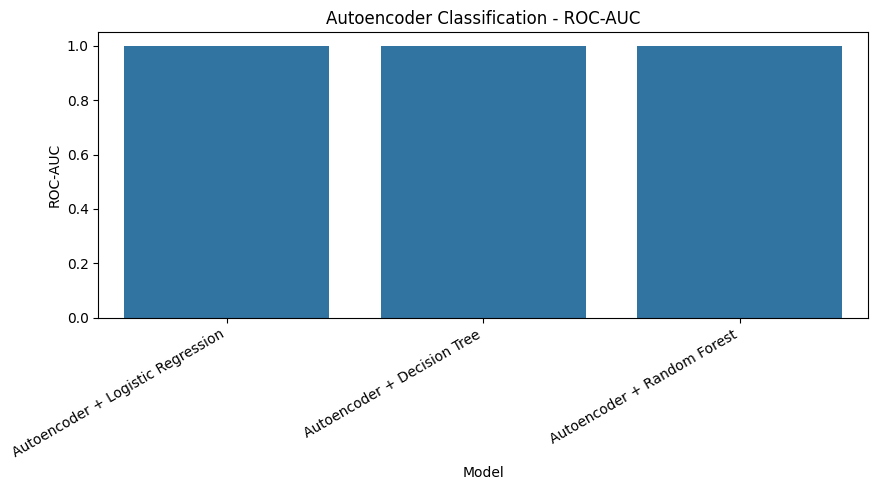

In [51]:
# Performance Visualization
metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
]

for metric in metrics_to_plot:

    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=ae_results,
        x="Model",
        y=metric
    )

    plt.xticks(
        rotation=30,
        ha="right"
    )

    plt.title(
        f"Autoencoder Classification - {metric}"
    )

    plt.tight_layout()

    plt.show()

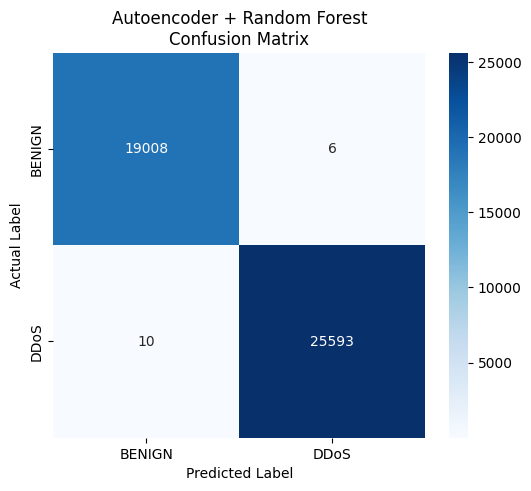

In [52]:
# Confusion Matrix for Random Forest

# Since Random Forest was one of your strongest conventional models, let's inspect its Autoencoder version.

y_pred_rf = rf_model.predict(X_test)

cm = confusion_matrix(
    y_test_encoded,
    y_pred_rf
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.title(
    "Autoencoder + Random Forest\nConfusion Matrix"
)

plt.show()

In [53]:
# Classification Report
print(
    classification_report(
        y_test_encoded,
        y_pred_rf,
        target_names=label_encoder.classes_
    )
)

              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00     19014
        DDoS       1.00      1.00      1.00     25603

    accuracy                           1.00     44617
   macro avg       1.00      1.00      1.00     44617
weighted avg       1.00      1.00      1.00     44617



In [54]:
# Compare Reconstruction Error and Classification

import pandas as pd
reconstruction_errors = pd.read_csv(
    "autoencoder_reconstruction_errors.csv"
)

print(
    reconstruction_errors.groupby("Label")
    ["Reconstruction_Error"]
    .mean()
)

Label
BENIGN    0.002018
DDoS      0.000205
Name: Reconstruction_Error, dtype: float64


In [55]:
# Feature Importance from Random Forest
# Random Forest can tell us which latent dimensions are most useful for classification.

latent_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

latent_importance = latent_importance.sort_values(
    "Importance",
    ascending=False
)

latent_importance

,Feature,Importance
0,Latent_1,0.271367
5,Latent_6,0.201809
6,Latent_7,0.140165
3,Latent_4,0.124698
1,Latent_2,0.104743
8,Latent_9,0.057690
15,Latent_16,0.024165
10,Latent_11,0.017206
14,Latent_15,0.013946
11,Latent_12,0.009805


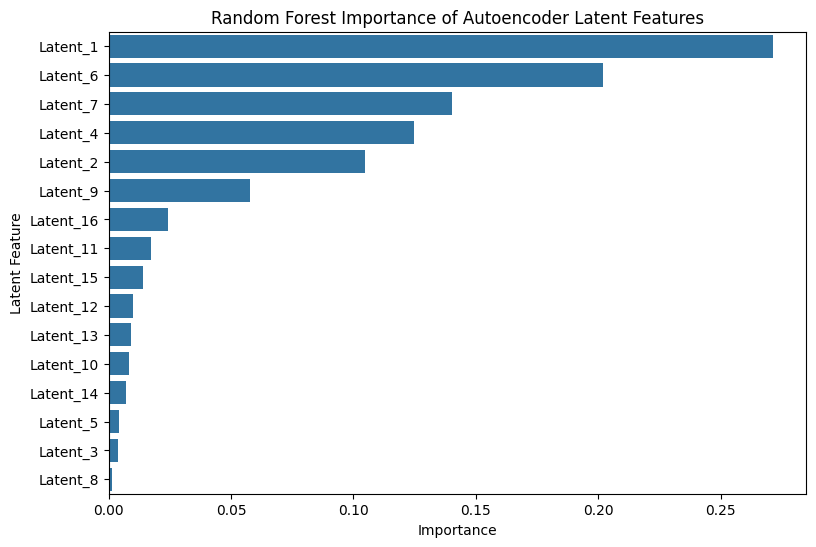

In [56]:
# Plot Latent Feature Importance
plt.figure(figsize=(9, 6))

sns.barplot(
    data=latent_importance,
    x="Importance",
    y="Feature"
)

plt.title(
    "Random Forest Importance of Autoencoder Latent Features"
)

plt.xlabel("Importance")
plt.ylabel("Latent Feature")

plt.show()

In [57]:
# Compare Original vs Autoencoder Feature Dimension
print(
    "Original selected features:",
    X.shape[1] if "X" in globals() else "See Notebook 04"
)

print(
    "Autoencoder latent features:",
    X_train.shape[1]
)

Original selected features: See Notebook 04
Autoencoder latent features: 16


In [58]:
print("Autoencoder latent dimensions:", X_train.shape[1])

Autoencoder latent dimensions: 16


In [59]:
ae_results.to_csv(
    "autoencoder_classification_results.csv",
    index=False
)

latent_importance.to_csv(
    "autoencoder_latent_feature_importance.csv",
    index=False
)

print("Autoencoder classification results saved.")

Autoencoder classification results saved.


## Conclusion

The Autoencoder-generated latent representations were
evaluated using Logistic Regression, Decision Tree,
and Random Forest classifiers.

This experiment determines whether compressed
representations learned through unsupervised learning
can retain information useful for DDoS classification.

The Autoencoder-based classifiers are compared using
Accuracy, Precision, Recall, F1-score, ROC-AUC, and
training time.

The results will be compared with the corresponding
classifiers trained directly on the selected original
features.

The Autoencoder approach will only be considered
beneficial if the reduced representation provides
competitive classification performance while offering
advantages such as dimensionality reduction or a
more compact representation.

The Autoencoder is not being used because labels are unavailable. We are investigating whether unsupervised representation learning can compress the network-flow features while preserving information useful for downstream DDoS classification. We then compare classifiers trained on the latent representation against classifiers trained on the original selected features.